# Vision Transformer (ViT) Demo Notebook
This notebook demonstrates the Vision Transformer workflow:
1. Splitting an image into patches.
2. Treating patches as tokens and feeding them into a Transformer.
3. Using a classification token to summarize the image.

It includes both a **diagram visualization** and a **hands-on exercise**.

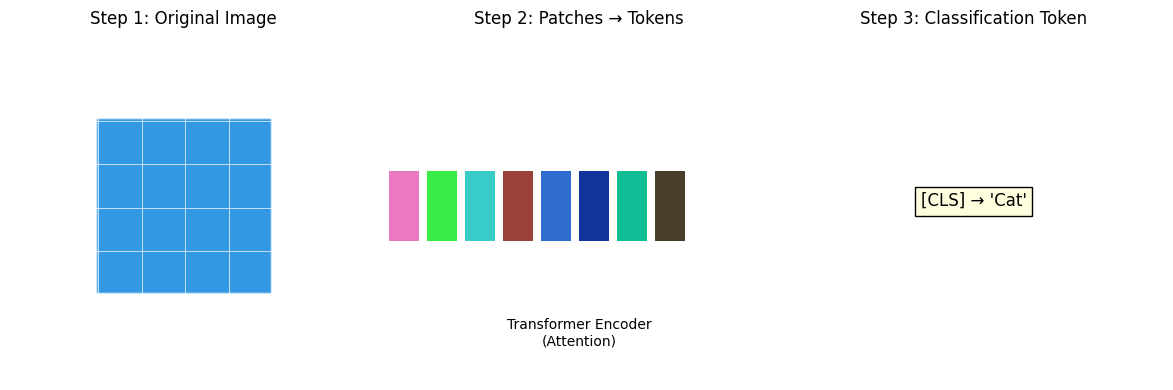

In [3]:
# Part 1: Diagram Visualization of ViT Workflow
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# Create a simple demo image (replace with your own if desired)
img = np.ones((128,128,3))
img[32:96,32:96] = [0.2, 0.6, 0.9]  # add a colored square patch

fig, ax = plt.subplots(1, 3, figsize=(12,4))

# Step 1: Original Image with patch grid
ax[0].imshow(img)
ax[0].set_title("Step 1: Original Image")
ax[0].axis("off")
for i in range(0,128,16):
    ax[0].axhline(i, color="white", lw=0.5)
    ax[0].axvline(i, color="white", lw=0.5)

# Step 2: Tokens flowing into Transformer
ax[1].set_title("Step 2: Patches → Tokens")
ax[1].axis("off")
for i in range(8):
    rect = patches.Rectangle((i*0.1,0.4),0.08,0.2,facecolor=np.random.rand(3,))
    ax[1].add_patch(rect)
ax[1].text(0.5,0.1,"Transformer Encoder\n(Attention)", ha="center", fontsize=10)

# Step 3: Classification Token
ax[2].set_title("Step 3: Classification Token")
ax[2].axis("off")
ax[2].text(0.5,0.5,"[CLS] → 'Cat'", ha="center", fontsize=12,
           bbox=dict(facecolor="lightyellow", edgecolor="black"))

plt.tight_layout()
plt.show()

Image shape: (128, 128, 3)
Number of patches: 64


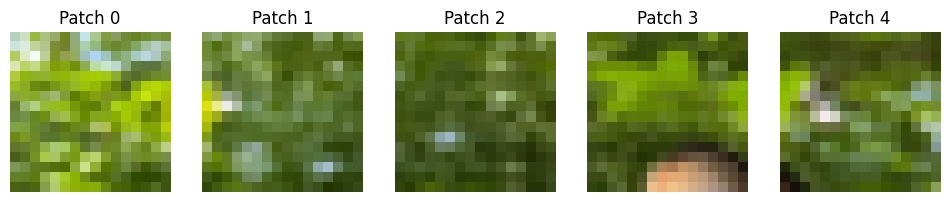

First patch as flattened token vector:
[182 210 190 205 225 193 157 184  62 171 193 123 152 170 104 113 132  36
 144 171 123 195 228 232 167 199 141 131 156  66 137 156  98 112 137  52
 103 131  38 113 141  50 123 148  68 116 143  56 204 227]


In [2]:
# Part 2: Hands-on Exercise – Splitting into Patches
from PIL import Image

# Load a sample image (replace with your own image path if desired)
img = Image.open("cat.jpg").resize((128,128))  # ensure 128x128
img_array = np.array(img)

patch_size = 16
num_patches = (img_array.shape[0] // patch_size) * (img_array.shape[1] // patch_size)

print(f"Image shape: {img_array.shape}")
print(f"Number of patches: {num_patches}")

# Function to split into patches
def split_into_patches(image, patch_size):
    patches = []
    for i in range(0, image.shape[0], patch_size):
        for j in range(0, image.shape[1], patch_size):
            patch = image[i:i+patch_size, j:j+patch_size]
            patches.append(patch)
    return np.array(patches)

patches = split_into_patches(img_array, patch_size)

# Show first few patches
fig, axes = plt.subplots(1,5, figsize=(12,3))
for idx, ax in enumerate(axes):
    ax.imshow(patches[idx])
    ax.set_title(f"Patch {idx}")
    ax.axis("off")
plt.show()

# Flatten patches into "tokens"
tokens = patches.reshape(patches.shape[0], -1)
print("First patch as flattened token vector:")
print(tokens[0][:50])  # print first 50 values for readability